# Analisis de viviendas

## Fase 1 - preparación

In [50]:
import os

import certifi
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import fetch_california_housing

os.environ["SSL_CERT_FILE"] = certifi.where()

In [51]:
datos = fetch_california_housing()

df_california = pd.DataFrame(datos.data, columns=datos.feature_names)
df_california["MedHouseVal"] = datos.target

df_california.head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [22]:
df_california.dtypes

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

In [23]:
df_california.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

## Fase 2 - análisis descriptivo

In [52]:
rango_edad = (
    float(df_california["HouseAge"].min()),
    float(df_california["HouseAge"].max()),
)
activar_filtro_latitud = False
latitud_minima = float(df_california["Latitude"].min())

# Aplicar los filtros a df_california.
df_filtrado = df_california[
    df_california["HouseAge"].between(rango_edad[0], rango_edad[1])
].copy()

if activar_filtro_latitud:
    df_filtrado = df_filtrado[df_filtrado["Latitude"] >= latitud_minima]

df_filtrado.head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [45]:
if df_filtrado.empty:
    resumen_fase_2 = pd.Series({"Registros filtrados": 0})
else:
    resumen_fase_2 = pd.Series(
        {
            "Registros filtrados": len(df_filtrado),
            "Mediana de MedHouseVal": df_filtrado["MedHouseVal"].median(),
            "Rango de MedHouseVal (máximo - mínimo)": (
                df_filtrado["MedHouseVal"].max() - df_filtrado["MedHouseVal"].min()
            ),
        }
    )

resumen_fase_2

Registros filtrados                       20640.00000
Mediana de MedHouseVal                        1.79700
Rango de MedHouseVal (máximo - mínimo)        4.85002
dtype: float64

## Fase 3 - visualización

### Gráfica de distribución

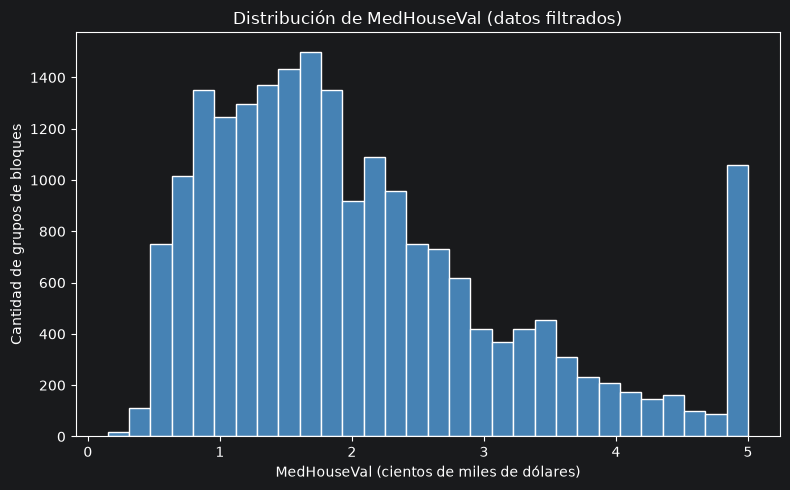

In [58]:
if df_filtrado.empty:
    print("No hay registros para mostrar en el histograma.")
else:
    figura_histograma, eje_histograma = plt.subplots(figsize=(8, 5))
    eje_histograma.hist(
        df_filtrado["MedHouseVal"],
        bins=30,
        color="steelblue",
        edgecolor="white",
    )
    eje_histograma.set_title("Distribución de MedHouseVal (datos filtrados)")
    eje_histograma.set_xlabel("MedHouseVal (cientos de miles de dólares)")
    eje_histograma.set_ylabel("Cantidad de grupos de bloques")
    figura_histograma.tight_layout()
    plt.show()
    plt.close(figura_histograma)

### Gráfica de dispersión

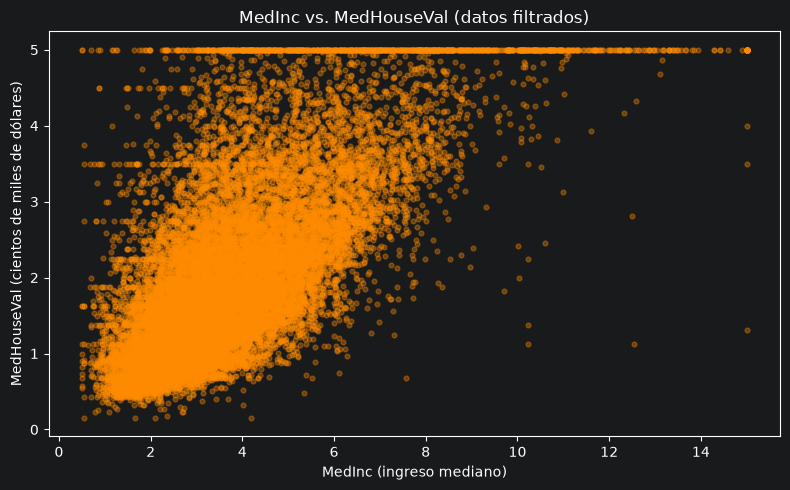

In [59]:
if df_filtrado.empty:
    print("No hay registros para mostrar en el gráfico de dispersión.")
else:
    figura_dispersion, eje_dispersion = plt.subplots(figsize=(8, 5))
    eje_dispersion.scatter(
        df_filtrado["MedInc"],
        df_filtrado["MedHouseVal"],
        alpha=0.35,
        s=12,
        color="darkorange",
    )
    eje_dispersion.set_title("MedInc vs. MedHouseVal (datos filtrados)")
    eje_dispersion.set_xlabel("MedInc (ingreso mediano)")
    eje_dispersion.set_ylabel("MedHouseVal (cientos de miles de dólares)")
    figura_dispersion.tight_layout()
    plt.show()
    plt.close(figura_dispersion)

### Mapa geográfico

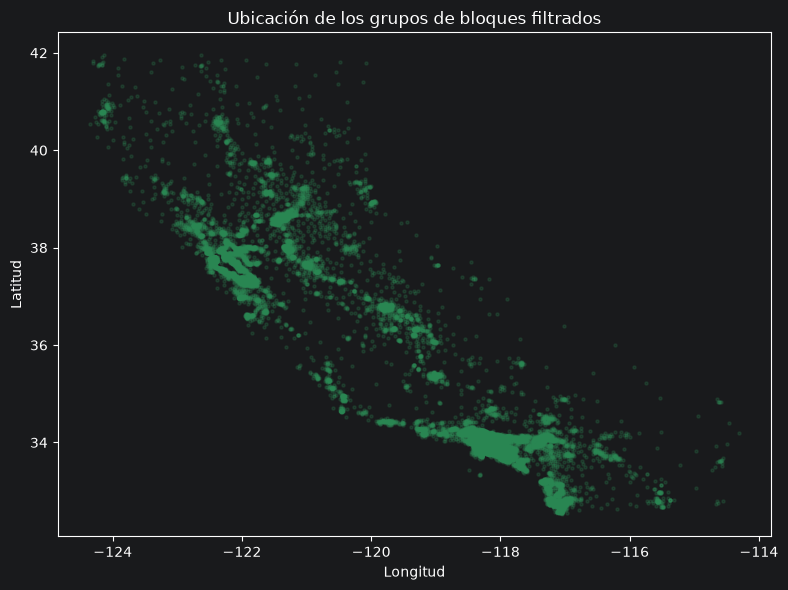

In [61]:
if df_filtrado.empty:
    print("No hay registros para mostrar en el mapa.")
else:
    figura_mapa, eje_mapa = plt.subplots(figsize=(8, 6))
    eje_mapa.scatter(
        df_filtrado["Longitude"],
        df_filtrado["Latitude"],
        alpha=0.2,
        s=5,
        color="seagreen",
    )
    eje_mapa.set_title("Ubicación de los grupos de bloques filtrados")
    eje_mapa.set_xlabel("Longitud")
    eje_mapa.set_ylabel("Latitud")
    figura_mapa.tight_layout()
    plt.show()
    plt.close(figura_mapa)